# Experimentos: Gossip Simulator

**Objetivo:** comparar Push, Push-Pull, Push + anti-entropy e fanout adaptativo + anti-entropy em cobertura, T50/T95 e tráfego, com o mesmo modelo de rede e o mesmo orçamento de bytes.

**Hipótese:** a política adaptativa reduz o tráfego redundante sem piorar cobertura e T95 de forma significativa.

**Ablação:** a variante `adaptive_ae_quiescent` suspende o Push depois de saturação local. Ela mede quanto tráfego a suspensão remove e se T95, cobertura e recuperação pioram.

**Escala:** o DOE principal usa N=50 a 500. Uma varredura separada (`doe_scale.csv`, 540 execuções) roda as seis variantes em N=1.000, 10.000 e 100.000, com os parâmetros congelados em N=50. Ela mede como T95 e o tráfego por nó crescem com N e se a economia do adaptativo se mantém.

**Fluxo:** validação do simulador, tuning com Optuna em N=50, congelamento dos parâmetros em `configs/tuned.yaml`, execução do DOE, varredura de escala e análise estatística.

**Especificação:** churn, perda, partição, orçamento, métricas e regras do tuning estão definidos no README, seções "Especificação do modelo" e "Fluxo experimental".

**Execução:** todas as células executam. O motor fica em `src/`; `experiments/helper.py` executa os manifestos e `experiments/tuning.py` roda os estudos Optuna. As etapas longas guardam os resultados em `results/` e não repetem o que já foi feito. Com `results/` preenchido, o notebook inteiro executa em poucos minutos. Sem `results/`, a varredura de escala leva horas; o README traz os comandos para rodar cada etapa pela linha de comando.

## 1. Imports e configuração

Os parâmetros ficam no YAML. O notebook só define os estudos Optuna e os gráficos. Regras de Gossip, transporte, coleta de métricas e agendamento de eventos ficam em `src/`.

In [1]:
import sys
import warnings
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from scipy import stats

warnings.filterwarnings("ignore", message="IProgress not found")  # barra de progresso do Optuna, não usada
import optuna

# o Optuna 4 marca `constraints_func` do TPESampler como experimental
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 80, "display.width", 200)

# o Jupyter costuma iniciar o kernel em experiments/; a raiz também funciona
ROOT = Path.cwd().resolve()
if ROOT.name == "experiments":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "experiments"))

from helper import BASE_CONFIG, BUDGET, RESULTS, run_manifest, run_trial, summarize_results
from tuning import FAMILIES, N_TRIALS, QUIESCENCE_GRID, TUNING_SCENARIOS, TUNING_SEEDS, tune_all

# seeds de treino separadas das do piloto (100..109) e do DOE (1000..1029)
assert not set(TUNING_SEEDS) & (set(range(100, 110)) | set(range(1000, 1030)))

VARIANTS = ["push_f1", "push_tuned", "push_pull", "push_ae", "adaptive_ae", "adaptive_ae_quiescent"]
PALETTE = dict(zip(VARIANTS, sns.color_palette("colorblind", len(VARIANTS))))

print("Famílias do tuning:", FAMILIES)
print("Trials por família:", N_TRIALS, "| seeds de treino:", TUNING_SEEDS)
print("Cenários do tuning:", TUNING_SCENARIOS, "| grade de quiescence_rounds:", QUIESCENCE_GRID)
BASE_CONFIG

Famílias do tuning: ('push_tuned', 'push_pull', 'push_ae', 'adaptive_ae')
Trials por família: 30 | seeds de treino: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9)
Cenários do tuning: ('stable', 'loss_5pct', 'churn_10pct') | grade de quiescence_rounds: (1, 2, 3, 4, 5, 6, 7, 8, 9, 10)


{'name': 'baseline',
 'simulation': {'duration_ms': 60000, 'gossip_interval_ms': 500},
 'network': {'nodes': 100,
  'topology': 'complete',
  'degree': 8,
  'latency_ms': [10, 10],
  'packet_loss': 0.0,
  'churn_fraction': 0.0,
  'churn_period_ms': 5000,
  'partition': None},
 'protocol': {'name': 'push',
  'fanout': 1,
  'ae_interval_ms': None,
  'adaptive': None},
 'update': {'size_bytes': 256, 'initial_infected': 1},
 'budget': {'bytes_per_node_per_interval': 4096, 'interval_ms': 1000}}

## 2. Validação do simulador

Rede completa sem falhas, `N=100`, Push com fanout 1 e 3. A curva simulada precisa acompanhar a analítica antes de qualquer tuning ou benchmark.

A recorrência abaixo é a aproximação de campo médio do Push em rodadas síncronas, da página 3 do PDF. A simulação usa 30 seeds (0 a 29). A rodada k ocorre em t = k × 500 ms e suas mensagens chegam 10 ms depois; por isso a amostra da curva simulada em t = (k + 1) × 500 ms corresponde à rodada k do modelo.

In [2]:
def analytic_push_coverage(n, fanout, rounds):
    """Cobertura esperada do Push em rede completa, sem falhas, em rodadas síncronas.

    Aproximação de campo médio: cada nó infectado escolhe `fanout` peers
    distintos, uniformemente, entre os outros n - 1 nós.
    """
    infected = [1.0]
    for _ in range(rounds):
        i = infected[-1]
        infected.append(i + (n - i) * (1 - (1 - fanout / (n - 1)) ** i))
    return [i / n for i in infected]


ROUNDS = 20
analytic_df = pd.DataFrame(
    [
        {"round": k, "coverage": c, "fanout": fanout}
        for fanout in (1, 3)
        for k, c in enumerate(analytic_push_coverage(100, fanout, ROUNDS))
    ]
)
assert analytic_df.groupby("fanout")["coverage"].last().gt(0.99).all()

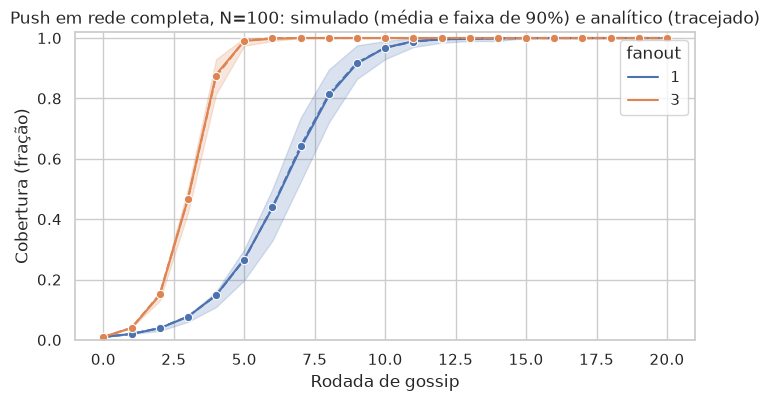

Maior diferença absoluta entre a média simulada e o modelo, por fanout:
fanout
1    0.0066
3    0.0057


In [3]:
interval_ms = BASE_CONFIG["simulation"]["gossip_interval_ms"]
curves = []
for fanout in (1, 3):
    config = deepcopy(BASE_CONFIG)  # rede completa, N=100, sem falhas
    config["protocol"].update(name="push", fanout=fanout, ae_interval_ms=None)
    for seed in range(30):
        summary, curve = run_trial(config, seed)
        assert summary["coverage_final"] == 1.0
        curves.append(curve.assign(fanout=fanout, seed=seed))
simulated_df = pd.concat(curves, ignore_index=True)
# a amostra em t = (k + 1) * 500 ms já inclui as entregas da rodada k
simulated_df["round"] = simulated_df["time_ms"] // interval_ms - 1
simulated_df = simulated_df[simulated_df["round"].between(0, ROUNDS)]

fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(
    data=simulated_df, x="round", y="coverage", hue="fanout",
    palette="deep", errorbar=("pi", 90), ax=ax,
)
sns.lineplot(
    data=analytic_df, x="round", y="coverage", hue="fanout",
    palette="deep", linestyle="--", marker="o", legend=False, ax=ax,
)
ax.set(
    xlabel="Rodada de gossip", ylabel="Cobertura (fração)", ylim=(0, 1.02),
    title="Push em rede completa, N=100: simulado (média e faixa de 90%) e analítico (tracejado)",
)
plt.show()

comparison = (
    simulated_df.groupby(["fanout", "round"])["coverage"].mean().rename("simulated").reset_index()
    .merge(analytic_df.rename(columns={"coverage": "analytic"}), on=["fanout", "round"])
)
comparison["abs_diff"] = (comparison["simulated"] - comparison["analytic"]).abs()
max_diff = comparison.groupby("fanout")["abs_diff"].max()
print("Maior diferença absoluta entre a média simulada e o modelo, por fanout:")
print(max_diff.round(4).to_string())
assert (max_diff < 0.02).all()

## 3. Tuning com Optuna em N=50

Um estudo por família de protocolo, com o mesmo número de trials (`N_TRIALS`) e as mesmas seeds de treino (`TUNING_SEEDS`). As famílias têm o nome da variante do DOE que usa os parâmetros: `push_tuned`, `push_pull`, `push_ae` e `adaptive_ae`. O README traz o espaço de busca de cada hiperparâmetro.

| Família | Hiperparâmetros |
|---|---|
| Push (`push_tuned`) | `fanout`, `gossip_interval_ms` |
| Push-Pull (`push_pull`) | `fanout`, `gossip_interval_ms` |
| Push + AE (`push_ae`) | `fanout`, `ae_interval_ms`, `gossip_interval_ms` |
| Adaptativo + AE (`adaptive_ae`) | `min_fanout`, `max_fanout`, `duplicate_threshold`, `timeout_threshold`, `ae_interval_ms` |

Cada trial executa 30 simulações em N=50: os 3 cenários de `TUNING_SCENARIOS` × 10 seeds, com orçamento fixo de 4.096 bytes por nó a cada 1.000 ms.

- **Objetivos:** média de `t95_ms` e média de `bytes_total` nas 30 simulações. Uma simulação sem T95 entra com `duration_ms`.
- **Restrição:** as 30 simulações atingem 95% de cobertura.
- **Tráfego:** o objetivo usa `bytes_total`, porque a quiescência só reduz os bytes enviados depois da saturação.

**Ablação da quiescência:** `adaptive_ae_quiescent` usa os parâmetros congelados de `adaptive_ae`, e `quiescence_rounds` é escolhido em uma grade de 1 a 10 (`QUIESCENCE_GRID`) com os mesmos cenários, seeds e objetivos. A diferença entre as duas variantes vem só da quiescência.

`tune_all` (`experiments/tuning.py`) roda os quatro estudos com `TPESampler(seed=0)` e a grade. Os estudos ficam em `results/tuning.db`; rodar a célula de novo retoma dos trials concluídos.

In [4]:
tuned, trials = tune_all(N_TRIALS, TUNING_SEEDS)

for family, table in trials.items():
    feasible = int((table["runs_without_t95"] == 0).sum())
    print(f"{family}: {len(table)} trials, {feasible} viáveis, {int(table['pareto'].sum())} na fronteira de Pareto")
assert all(len(trials[family]) == N_TRIALS for family in FAMILIES)

push_tuned: 30 trials, 30 viáveis, 30 na fronteira de Pareto
push_pull: 30 trials, 30 viáveis, 26 na fronteira de Pareto
push_ae: 30 trials, 30 viáveis, 25 na fronteira de Pareto
adaptive_ae: 30 trials, 30 viáveis, 8 na fronteira de Pareto
adaptive_ae_quiescent: 10 trials, 10 viáveis, 2 na fronteira de Pareto


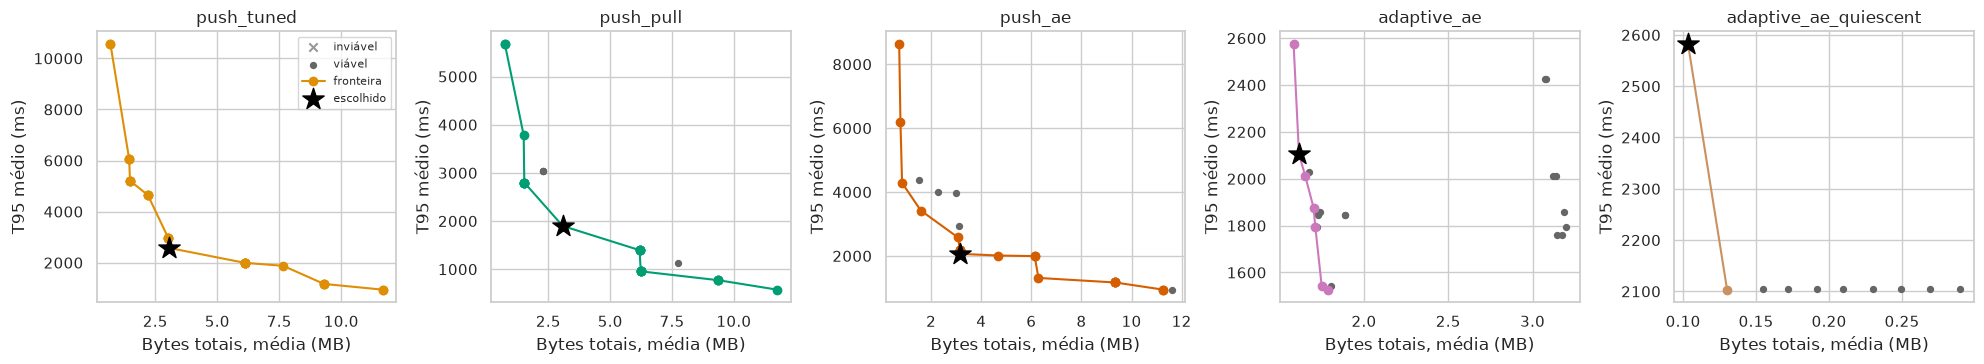

In [5]:
# inviáveis (x), viáveis (ponto), fronteira de Pareto (linha), escolhido (estrela)
fig, axes = plt.subplots(1, len(trials), figsize=(4 * len(trials), 3.8))
for ax, (family, table) in zip(axes, trials.items()):
    megabytes = table["bytes_total"] / 1e6
    feasible = table["runs_without_t95"] == 0
    ax.scatter(megabytes[~feasible], table.loc[~feasible, "t95_ms"], marker="x", color="0.6", label="inviável")
    ax.scatter(megabytes[feasible], table.loc[feasible, "t95_ms"], color="0.4", s=18, label="viável")
    front = table[table["pareto"]].sort_values("bytes_total")
    ax.plot(front["bytes_total"] / 1e6, front["t95_ms"], marker="o", color=PALETTE[family], label="fronteira")
    chosen = table[table["selected"]]
    ax.scatter(chosen["bytes_total"] / 1e6, chosen["t95_ms"], marker="*", s=260, color="black", zorder=3, label="escolhido")
    ax.set(title=family, xlabel="Bytes totais, média (MB)", ylabel="T95 médio (ms)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Exportação dos parâmetros otimizados

Cada família fica com uma única configuração, gravada em `configs/tuned.yaml`. A regra de escolha está fixada no README e implementada em `tuning.select_trial`: entre os trials viáveis da fronteira de Pareto, normalizar os dois objetivos entre 0 e 1 e escolher o trial mais próximo de (0, 0); em empate, o de menor `bytes_total`.

A mesma regra escolhe `quiescence_rounds` na grade da ablação.

Depois da exportação, os parâmetros não são reajustados com base nos resultados do DOE. No DOE, `push_f1` é o baseline fixo sem tuning; `push_tuned`, `push_pull`, `push_ae`, `adaptive_ae` e `adaptive_ae_quiescent` leem `configs/tuned.yaml`.

In [6]:
with (ROOT / "configs" / "tuned.yaml").open("w", encoding="utf-8") as f:
    yaml.safe_dump(tuned, f, sort_keys=False)

# objetivos do trial escolhido: médias de 30 simulações em N=50
chosen = pd.DataFrame(
    {family: table[table["selected"]].iloc[0] for family, table in trials.items()}
).T[["t95_ms", "bytes_total", "runs_without_t95"]]
table = pd.DataFrame(tuned).T.join(chosen).astype(object)
display(table.where(table.notna(), "-"))  # "-" = hiperparâmetro que a família não tem

# grade da ablação: adaptive_ae congelado, só quiescence_rounds varia
display(trials["adaptive_ae_quiescent"].sort_values("quiescence_rounds").drop(columns="number"))

,fanout,gossip_interval_ms,ae_interval_ms,min_fanout,max_fanout,duplicate_threshold,timeout_threshold,quiescence_rounds,t95_ms,bytes_total,runs_without_t95
push_tuned,1.0,250.0,-,-,-,-,-,-,2576.666667,3055820.266667,0
push_pull,2.0,500.0,-,-,-,-,-,-,1897.333333,3079604.8,0
push_ae,1.0,250.0,1000.0,-,-,-,-,-,2064.666667,3166552.533333,0
adaptive_ae,-,-,2000.0,1.0,3.0,0.377015,0.676057,-,2105.333333,1614411.733333,0
adaptive_ae_quiescent,-,-,2000.0,1.0,3.0,0.377015,0.676057,1.0,2583.0,103306.666667,0


,quiescence_rounds,t95_ms,bytes_total,runs_without_t95,pareto,selected
8,1,2583.000000,103306.666667,0,True,True
4,2,2103.333333,130103.466667,0,True,False
0,3,2105.333333,154426.666667,0,False,False
7,4,2105.333333,172086.400000,0,False,False
2,5,2105.333333,191512.533333,0,False,False
9,6,2105.333333,209725.333333,0,False,False
5,7,2105.333333,229848.000000,0,False,False
6,8,2105.333333,249167.466667,0,False,False
1,9,2105.333333,268842.666667,0,False,False
3,10,2105.333333,289937.600000,0,False,False


## 5. Carregamento do DOE

Os manifestos em `experiments/doe/` são gerados por `python experiments/doe.py --out experiments/doe`. O notebook carrega os manifestos prontos e não mantém uma lista própria de cenários.

Seeds do piloto: 100..109. Seeds de teste do DOE: 1000..1029.

Seis variantes: `push_f1` (baseline fixo), `push_tuned`, `push_pull`, `push_ae`, `adaptive_ae` e `adaptive_ae_quiescent`. O piloto usa as cinco variantes com tuning.

`doe_scale.csv` é a varredura de escala: cenários estável, perda de 5% e churn de 10%, seis variantes, N=1.000, 10.000 e 100.000, orçamento de 4.096 bytes, seeds 1000..1009. São 540 execuções, fora das 17.640 do plano principal.

In [7]:
DOE_DIR = ROOT / "experiments" / "doe"
pilot_plan = pd.read_csv(DOE_DIR / "doe_pilot.csv")
full_plan = pd.read_csv(DOE_DIR / "doe_runs.csv")
scale_plan = pd.read_csv(DOE_DIR / "doe_scale.csv")

assert len(pilot_plan) == 600
assert len(full_plan) == 17_640
assert len(scale_plan) == 540

display(pilot_plan.groupby(["scenario", "protocol_variant"]).size().unstack())
display(full_plan.groupby(["phase", "n_nodes"]).size().unstack())
display(scale_plan.groupby(["scenario", "n_nodes"]).size().unstack())

protocol_variant,adaptive_ae,adaptive_ae_quiescent,push_ae,push_pull,push_tuned
scenario,,,,,
churn_10pct,20,20,20,20,20
latency_10_200ms,20,20,20,20,20
loss_5_churn_10,20,20,20,20,20
loss_5pct,20,20,20,20,20
stable,20,20,20,20,20
temporary_partition,20,20,20,20,20


n_nodes,50,100,250,500
phase,,,,
interaction,NaN,1620.0,NaN,1620.0
main,3600.0,3600.0,3600.0,3600.0


n_nodes,1000,10000,100000
scenario,,,
churn_10pct,60,60,60
loss_5pct,60,60,60
stable,60,60,60


## 6. Execução do piloto e do benchmark completo

Rodar primeiro o piloto de 600 execuções com os parâmetros congelados e inspecionar a qualidade dos dados. Só depois rodar as 17.640 execuções.

Não descartar execuções que não atingem 95% de cobertura: registrar `t95_ms = NaN` e reportar a fração que atingiu 95%. A coorte elegível da cobertura são os nós online no instante. Confirmar que todos os protocolos obedecem ao orçamento (dados + controle + reparos); a coluna `budget_drops` conta as mensagens barradas.

A varredura de escala roda por último. O custo de uma execução cresce com o número de mensagens, que é proporcional a N. As 180 execuções de N=100.000 concentram quase todo o tempo: de 100 s (`adaptive_ae_quiescent`) a 730 s (`push_ae`) por execução, medido com 14 a 22 execuções em paralelo.

As três chamadas de `run_manifest` abaixo leem os resultados de `results/` quando eles existem. `wall_time_s` foi medido na execução original, não na leitura.

In [8]:
def check_quality(summary_df, coverage_df, plan):
    """Confere o contrato dos resultados e mostra a fração de execuções com T95."""
    assert len(summary_df) == len(plan)
    assert summary_df["coverage_final"].between(0, 1).all()
    assert coverage_df["coverage"].between(0, 1).all()
    # checagem agregada (teto × N × janelas de 1.000 ms): não pega um nó isolado acima do teto
    limit = plan[BUDGET].to_numpy() * plan["n_nodes"].to_numpy() * plan["duration_ms"].to_numpy() / 1000
    assert (summary_df["bytes_total"].to_numpy() <= limit).all()
    reached = (
        summary_df.assign(reached_t95=summary_df["t95_ms"].notna())
        .groupby(["scenario", "protocol_variant"])["reached_t95"]
        .mean()
        .unstack()[[v for v in VARIANTS if v in set(summary_df["protocol_variant"])]]
    )
    print("Fração de execuções que atingiram 95% de cobertura:")
    display(reached)


# retoma de results/: só roda as linhas que faltam
pilot_summary, pilot_coverage = run_manifest(pilot_plan, tuned, RESULTS / "doe_pilot")
check_quality(pilot_summary, pilot_coverage, pilot_plan)
display(
    summarize_results(pilot_summary, by=("scenario", "protocol_variant", "n_nodes"))[
        ["scenario", "protocol_variant", "n_nodes", "t95_ms_median", "bytes_total_median", "budget_drops_median", "timeouts_median"]
    ].query("n_nodes == 500")
)

Fração de execuções que atingiram 95% de cobertura:


protocol_variant,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
scenario,,,,,
churn_10pct,1.0,1.0,1.0,1.0,1.0
latency_10_200ms,1.0,1.0,1.0,1.0,1.0
loss_5_churn_10,1.0,1.0,1.0,1.0,1.0
loss_5pct,1.0,1.0,1.0,1.0,1.0
stable,1.0,1.0,1.0,1.0,1.0
temporary_partition,1.0,1.0,1.0,1.0,1.0


,scenario,protocol_variant,n_nodes,t95_ms_median,bytes_total_median,budget_drops_median,timeouts_median
1,churn_10pct,adaptive_ae,500,3510.0,14810720.0,0.0,1239.5
3,churn_10pct,adaptive_ae_quiescent,500,4010.0,1030400.0,0.0,1262.0
5,churn_10pct,push_ae,500,3020.0,29052280.0,0.0,2591.5
7,churn_10pct,push_pull,500,2520.0,28309816.0,0.0,0.0
9,churn_10pct,push_tuned,500,3885.0,27864088.0,0.0,0.0
11,latency_10_200ms,adaptive_ae,500,3127.0,16454616.0,0.0,0.0
13,latency_10_200ms,adaptive_ae_quiescent,500,3656.5,976472.0,0.0,0.0
15,latency_10_200ms,push_ae,500,3050.5,32349056.0,0.0,0.0
17,latency_10_200ms,push_pull,500,2583.0,31589376.0,0.0,0.0
19,latency_10_200ms,push_tuned,500,3698.0,31066344.0,0.0,0.0


In [9]:
# benchmark completo: 17.640 execuções
summary_df, coverage_df = run_manifest(full_plan, tuned, RESULTS / "doe_runs")
check_quality(summary_df, coverage_df, full_plan)

# fatores do manifesto que o summary_df não tem
factors = full_plan[["run_id", "phase", BUDGET, "packet_loss", "churn_fraction"]]
summary_df = summary_df.merge(factors, on="run_id")
print(f"Tempo de CPU das 17.640 execuções: {summary_df['wall_time_s'].sum() / 3600:.1f} h")

Fração de execuções que atingiram 95% de cobertura:


protocol_variant,push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
scenario,,,,,,
churn_10pct,1.0,1.0,1.0,1.0,1.0,1.0
churn_20pct,1.0,1.0,1.0,1.0,1.0,1.0
churn_5pct,1.0,1.0,1.0,1.0,1.0,1.0
latency_10_100ms,1.0,1.0,1.0,1.0,1.0,1.0
latency_10_200ms,1.0,1.0,1.0,1.0,1.0,1.0
loss_10_churn_10,1.0,1.0,1.0,1.0,1.0,1.0
loss_10_churn_20,1.0,1.0,1.0,1.0,1.0,1.0
loss_10_churn_5,1.0,1.0,1.0,1.0,1.0,1.0
loss_10pct,1.0,1.0,1.0,1.0,1.0,1.0


Tempo de CPU das 17.640 execuções: 4.9 h


In [10]:
# varredura de escala: 540 execuções em N=1.000, 10.000 e 100.000
# 14 processos: cada execução de N=100.000 ocupa cerca de 300 MB
scale_summary, scale_coverage = run_manifest(scale_plan, tuned, RESULTS / "doe_scale", workers=14)
check_quality(scale_summary, scale_coverage, scale_plan)
display(
    scale_summary.groupby(["n_nodes", "protocol_variant"])["wall_time_s"]
    .median().unstack()[VARIANTS].round(1)
    .rename_axis(index="N", columns="Tempo de execução, mediana (s)")
)
print(f"Tempo de CPU das 540 execuções: {scale_summary['wall_time_s'].sum() / 3600:.1f} h")

Fração de execuções que atingiram 95% de cobertura:


protocol_variant,push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
scenario,,,,,,
churn_10pct,1.0,1.0,1.0,1.0,1.0,1.0
loss_5pct,1.0,1.0,1.0,1.0,1.0,1.0
stable,1.0,1.0,1.0,1.0,1.0,1.0


"Tempo de execução, mediana (s)",push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
N,,,,,,
1000,1.0,3.1,4.9,4.5,3.9,0.6
10000,18.1,45.5,62.7,82.8,29.4,11.7
100000,187.0,471.7,614.3,729.1,402.5,98.3


Tempo de CPU das 540 execuções: 23.6 h


## 7. Análise estatística e visualizações

A análise agrega por cenário e variante e reporta mediana, quartis e fração de execuções com T95. Os casos em que o adaptativo perde para algum baseline aparecem na seção 7.1.

- `main` é a fase principal do DOE: 10 cenários × 6 variantes × 4 tamanhos × 2 orçamentos × 30 seeds = 14.400 execuções.
- As tabelas e os gráficos por cenário usam N=100 e orçamento de 4.096 bytes, com 30 seeds por célula. As comparações pareadas usam os quatro tamanhos e os dois orçamentos.
- O tráfego tem duas colunas. `bytes_until_t95` é o custo de disseminar a atualização e não depende de `duration_ms`. `bytes_total` inclui o tráfego redundante depois da saturação e cresce com `duration_ms` nas variantes que nunca param de enviar.
- `wall_time_s` é o tempo real da execução e mede o custo do simulador, não do protocolo. As execuções rodaram em paralelo, então o valor inclui a disputa por CPU.

In [11]:
main = summary_df[summary_df["phase"] == "main"]
SCENARIOS = list(dict.fromkeys(main["scenario"]))  # ordem do manifesto


def scenario_table(metric, n_nodes=100, budget=4096, scale=1.0):
    """Tabela cenário × variante de uma coluna de `summarize_results`, em um N e um orçamento."""
    data = main[(main["n_nodes"] == n_nodes) & (main[BUDGET] == budget)]
    table = summarize_results(data).pivot(index="scenario", columns="protocol_variant", values=metric)
    return (table.loc[SCENARIOS, VARIANTS] * scale).round(2)


print("Fração de execuções com T95, todas as 14.400 execuções da fase principal:")
display(
    main.assign(reached=main["t95_ms"].notna()).groupby(["scenario", "protocol_variant"])["reached"]
    .mean().unstack().loc[SCENARIOS, VARIANTS].round(3)
)
print("Mediana de T95 (ms), N=100, orçamento de 4.096 bytes, 30 seeds por célula:")
display(scenario_table("t95_ms_median"))
print("Mediana de bytes até T95 (kB), N=100, orçamento de 4.096 bytes:")
display(scenario_table("bytes_until_t95_median", scale=1e-3))
print("Mediana de bytes totais em 60 s (MB), N=100, orçamento de 4.096 bytes:")
display(scenario_table("bytes_total_median", scale=1e-6))
print("Mediana do overhead de controle (bytes_control / bytes_total), N=100, orçamento de 4.096 bytes:")
display(scenario_table("control_overhead_median"))
print("Mediana de DATA duplicadas, N=100, orçamento de 4.096 bytes:")
display(scenario_table("duplicates_median"))

Fração de execuções com T95, todas as 14.400 execuções da fase principal:


protocol_variant,push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
scenario,,,,,,
stable,1.0,1.0,1.0,1.0,1.0,1.0
loss_1pct,1.0,1.0,1.0,1.0,1.0,1.0
loss_5pct,1.0,1.0,1.0,1.0,1.0,1.0
loss_10pct,1.0,1.0,1.0,1.0,1.0,1.0
latency_10_100ms,1.0,1.0,1.0,1.0,1.0,1.0
latency_10_200ms,1.0,1.0,1.0,1.0,1.0,1.0
churn_5pct,1.0,1.0,1.0,1.0,1.0,1.0
churn_10pct,1.0,1.0,1.0,1.0,1.0,1.0
churn_20pct,1.0,1.0,1.0,1.0,1.0,1.0


Mediana de T95 (ms), N=100, orçamento de 4.096 bytes, 30 seeds por célula:


protocol_variant,push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
scenario,,,,,,
stable,5510.0,2760.0,2020.0,2030.0,2510.0,2510.0
loss_1pct,5510.0,2760.0,2020.0,2030.0,2510.0,2510.0
loss_5pct,6010.0,3010.0,2020.0,2260.0,2510.0,2510.0
loss_10pct,6010.0,3010.0,2265.0,2260.0,2510.0,3010.0
latency_10_100ms,5575.0,2825.0,2051.5,2125.5,2531.5,2548.5
latency_10_200ms,5647.5,2897.5,2098.0,2263.0,2543.0,2597.0
churn_5pct,6010.0,3010.0,2020.0,2030.0,2510.0,3010.0
churn_10pct,6510.0,3010.0,2020.0,2260.0,2510.0,3010.0
churn_20pct,7010.0,3260.0,2020.0,2510.0,3010.0,3510.0


Mediana de bytes até T95 (kB), N=100, orçamento de 4.096 bytes:


protocol_variant,push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
scenario,,,,,,
stable,101.86,101.86,94.06,77.85,114.10,80.06
loss_1pct,101.59,101.59,93.13,79.96,112.77,80.58
loss_5pct,104.99,104.99,93.28,84.82,108.64,81.80
loss_10pct,108.94,108.94,104.97,92.84,107.28,91.83
latency_10_100ms,101.86,101.86,99.30,78.07,110.15,75.62
latency_10_200ms,101.86,101.86,99.42,91.14,110.16,75.27
churn_5pct,112.06,100.91,90.98,75.90,103.39,84.33
churn_10pct,111.11,101.46,90.17,80.21,100.88,83.35
churn_20pct,107.44,103.09,81.52,91.82,103.85,81.55


... (2 outputs left out)

Mediana do overhead de controle (bytes_control / bytes_total), N=100, orçamento de 4.096 bytes:


protocol_variant,push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
scenario,,,,,,
stable,0.0,0.0,0.00,0.03,0.03,0.46
loss_1pct,0.0,0.0,0.00,0.03,0.03,0.45
loss_5pct,0.0,0.0,0.00,0.03,0.03,0.44
loss_10pct,0.0,0.0,0.00,0.03,0.03,0.41
latency_10_100ms,0.0,0.0,0.00,0.03,0.03,0.47
latency_10_200ms,0.0,0.0,0.00,0.03,0.03,0.47
churn_5pct,0.0,0.0,0.00,0.03,0.03,0.41
churn_10pct,0.0,0.0,0.00,0.03,0.03,0.37
churn_20pct,0.0,0.0,0.00,0.03,0.02,0.29


Mediana de DATA duplicadas, N=100, orçamento de 4.096 bytes:


protocol_variant,push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
scenario,,,,,,
stable,11062.0,23062.0,23209.5,23251.0,11777.0,307.5
loss_1pct,10951.5,22832.0,22976.0,23016.0,11656.5,304.0
loss_5pct,10477.5,21878.5,22019.5,22066.0,11183.5,303.0
loss_10pct,9890.5,20681.0,20839.0,20860.5,10602.5,322.5
latency_10_100ms,11062.0,23062.0,23261.5,23263.0,11775.0,283.0
latency_10_200ms,11062.0,23062.0,23260.5,23243.0,11775.5,282.0
churn_5pct,9951.0,20773.0,20909.5,20968.0,10628.5,343.0
churn_10pct,8877.0,18583.5,18749.0,18779.5,9542.5,349.0
churn_20pct,6945.5,14620.5,14772.0,14754.0,7567.0,375.5


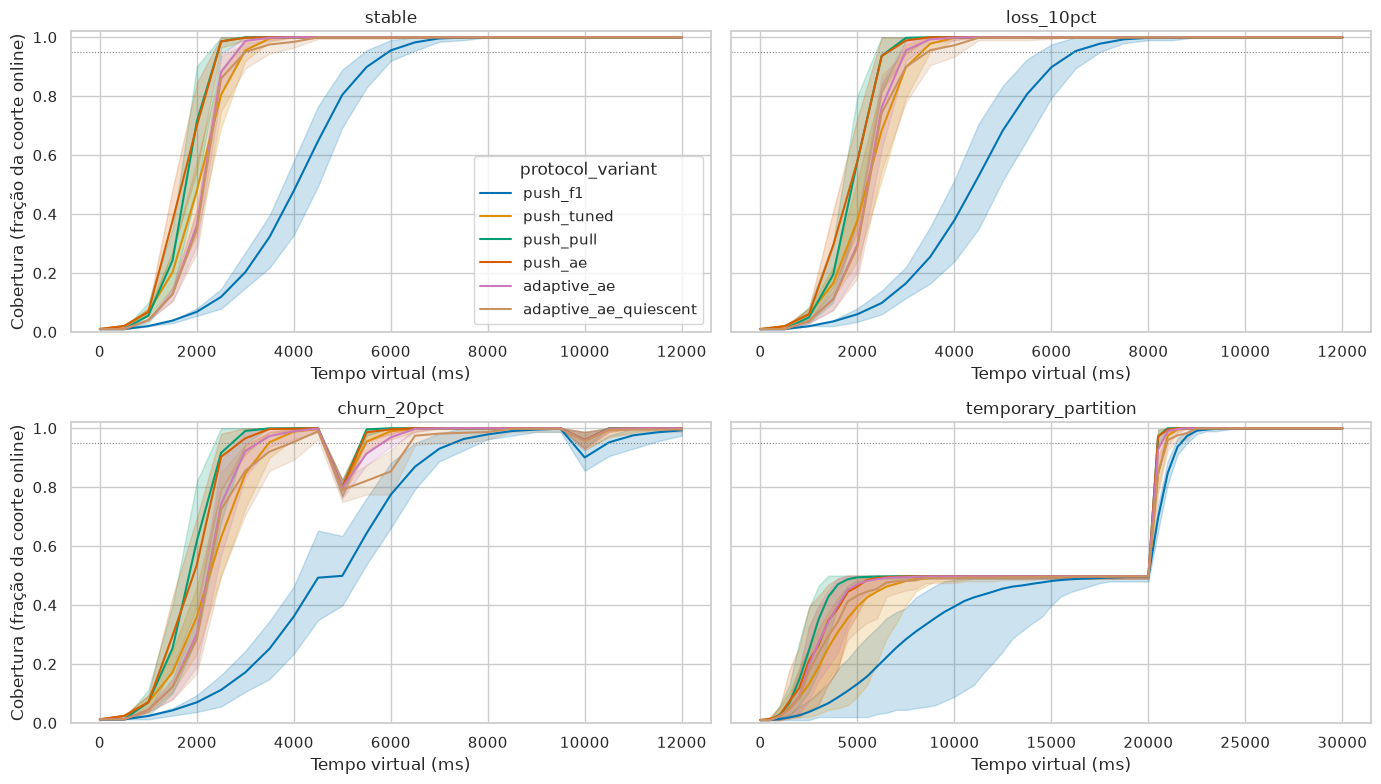

In [12]:
# cobertura × tempo, N=100, orçamento de 4.096 bytes: média de 30 seeds e faixa entre os percentis 5 e 95
panels = ["stable", "loss_10pct", "churn_20pct", "temporary_partition"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
for ax, scenario in zip(axes.flat, panels):
    runs = full_plan.query(f"phase == 'main' and scenario == @scenario and n_nodes == 100 and {BUDGET} == 4096")
    data = coverage_df[coverage_df["run_id"].isin(runs["run_id"])]
    limit_ms = 30_000 if scenario == "temporary_partition" else 12_000
    sns.lineplot(
        data=data[data["time_ms"] <= limit_ms], x="time_ms", y="coverage",
        hue="protocol_variant", hue_order=VARIANTS, palette=PALETTE,
        estimator="mean", errorbar=("pi", 90), ax=ax, legend=scenario == "stable",
    )
    ax.axhline(0.95, color="0.5", linewidth=0.8, linestyle=":")
    ax.set(title=scenario, xlabel="Tempo virtual (ms)", ylabel="Cobertura (fração da coorte online)", ylim=(0, 1.02))
plt.tight_layout()
plt.show()

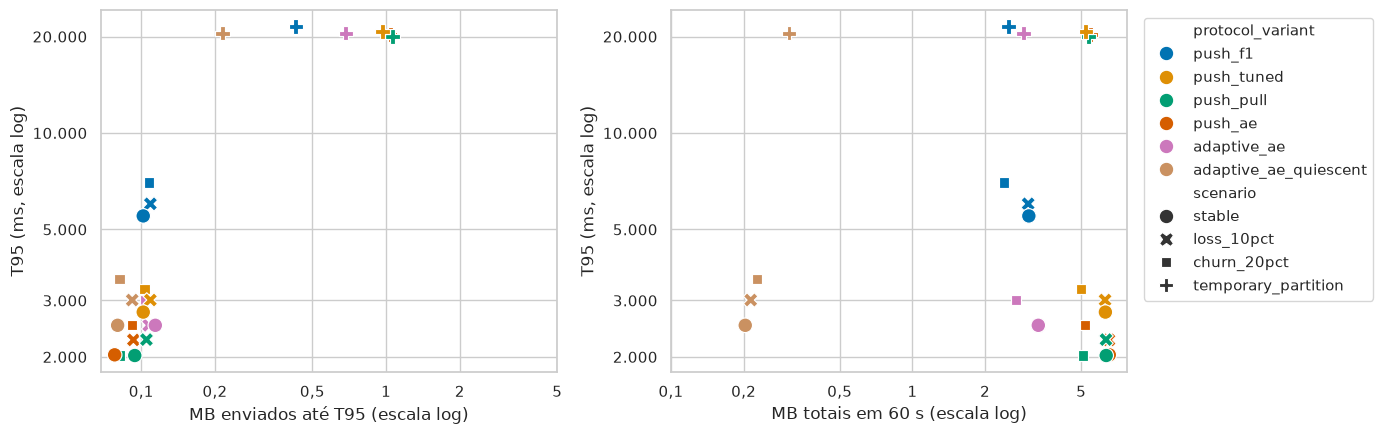

In [13]:
# T95 × tráfego, N=100, orçamento de 4.096 bytes: mediana de 30 seeds por variante
# esquerda: bytes até T95 (custo de disseminar); direita: bytes totais em 60 s, com o tráfego pós-saturação
data = main[(main["n_nodes"] == 100) & (main[BUDGET] == 4096) & main["scenario"].isin(panels)]
medians = data.groupby(["scenario", "protocol_variant"])[["t95_ms", "bytes_until_t95", "bytes_total"]].median().reset_index()
medians["mb_until_t95"] = medians["bytes_until_t95"] / 1e6
medians["mb_total"] = medians["bytes_total"] / 1e6
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, column, label in (
    (axes[0], "mb_until_t95", "MB enviados até T95 (escala log)"),
    (axes[1], "mb_total", "MB totais em 60 s (escala log)"),
):
    sns.scatterplot(
        data=medians, x=column, y="t95_ms", hue="protocol_variant", hue_order=VARIANTS,
        palette=PALETTE, style="scenario", style_order=panels, s=110, ax=ax, legend=ax is axes[1],
    )
    ax.set(xscale="log", yscale="log", xlabel=label, ylabel="T95 (ms, escala log)")
    ax.minorticks_off()
    ax.set_xticks([0.1, 0.2, 0.5, 1, 2, 5], labels=["0,1", "0,2", "0,5", "1", "2", "5"])
    ax.set_yticks([2000, 3000, 5000, 10000, 20000], labels=["2.000", "3.000", "5.000", "10.000", "20.000"])
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

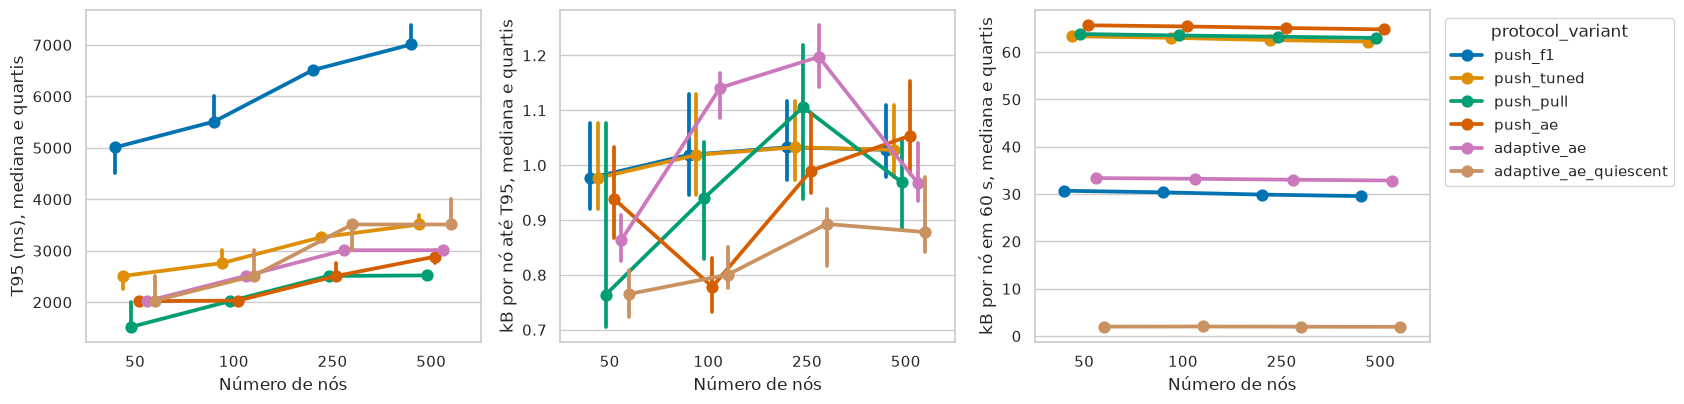

In [14]:
# efeito do tamanho da rede no DOE principal (parâmetros ajustados em N=50), cenário estável,
# orçamento de 4.096 bytes: mediana e quartis de 30 seeds
data = main[(main["scenario"] == "stable") & (main[BUDGET] == 4096)].assign(
    kb_per_node_until_t95=lambda d: d["bytes_until_t95"] / d["n_nodes"] / 1e3,
    kb_per_node_total=lambda d: d["bytes_total"] / d["n_nodes"] / 1e3,
)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, column, label in (
    (axes[0], "t95_ms", "T95 (ms)"),
    (axes[1], "kb_per_node_until_t95", "kB por nó até T95"),
    (axes[2], "kb_per_node_total", "kB por nó em 60 s"),
):
    sns.pointplot(
        data=data, x="n_nodes", y=column, hue="protocol_variant", hue_order=VARIANTS,
        palette=PALETTE, estimator="median", errorbar=("pi", 50), dodge=0.4, ax=ax,
        legend=ax is axes[2],
    )
    ax.set(xlabel="Número de nós", ylabel=label + ", mediana e quartis")
sns.move_legend(axes[2], "upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### 7.1 Comparação pareada do adaptativo com os baselines

Cada execução de `adaptive_ae` é pareada com a execução do baseline no mesmo cenário, N, orçamento e seed. A mesma seed dá a mesma topologia, o mesmo nó de origem e o mesmo cronograma de churn. A razão `adaptive_ae / baseline` de cada par é resumida pela mediana: abaixo de 1, o adaptativo é melhor (menor T95 ou menos bytes).

O teste de Wilcoxon pareado (bilateral) verifica se a diferença entre os pares é sistemática. São 240 pares por cenário (4 tamanhos × 2 orçamentos × 30 seeds). Os valores-p não têm correção para comparações múltiplas; com 10 cenários e 2 métricas, usar 0,05 / 20 = 0,0025 como limiar de Bonferroni.

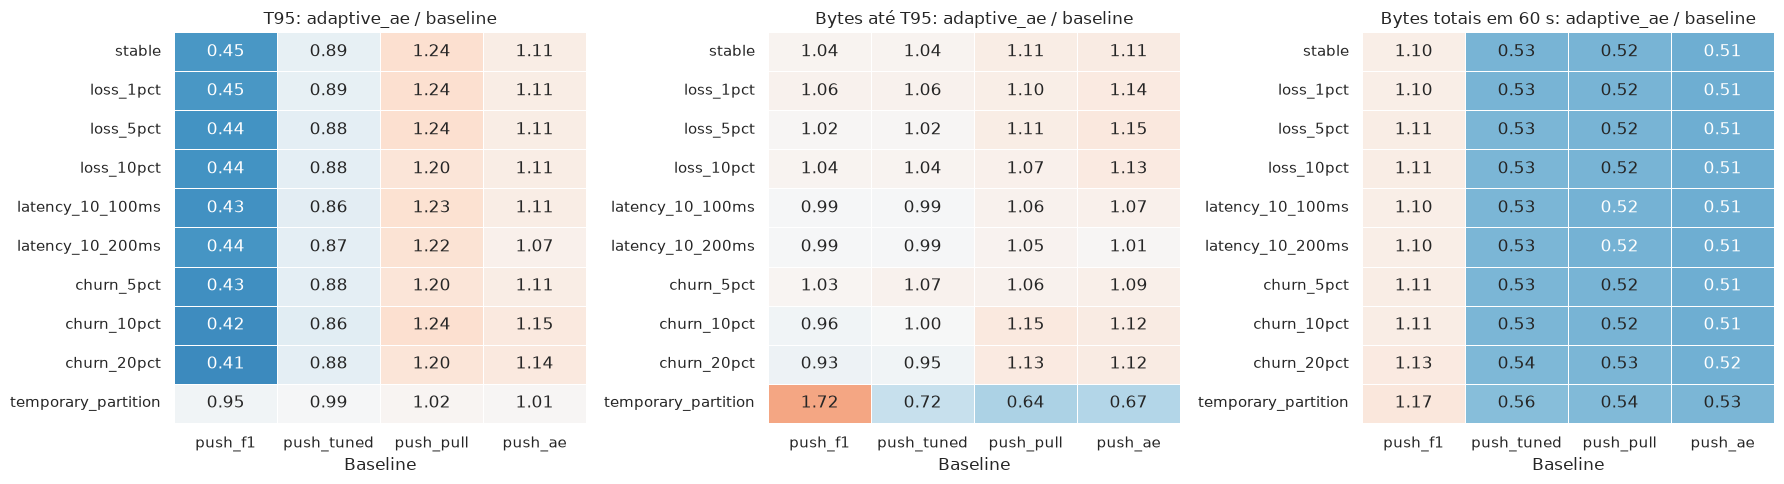

Fração dos pares em que adaptive_ae é pior que o baseline (T95 maior ou mais bytes totais):


metric,t95_ms,bytes_total,t95_ms,bytes_total,t95_ms,bytes_total,t95_ms,bytes_total
baseline,push_f1,push_f1,push_tuned,push_tuned,push_pull,push_pull,push_ae,push_ae
scenario,,,,,,,,
stable,0.0,1.0,0.05,0.0,0.95,0.0,0.77,0.0
loss_1pct,0.0,1.0,0.03,0.0,0.96,0.0,0.78,0.0
loss_5pct,0.0,1.0,0.02,0.0,0.88,0.0,0.79,0.0
loss_10pct,0.0,1.0,0.04,0.0,0.85,0.0,0.67,0.0
latency_10_100ms,0.0,1.0,0.04,0.0,1.00,0.0,0.92,0.0
latency_10_200ms,0.0,1.0,0.03,0.0,1.00,0.0,0.87,0.0
churn_5pct,0.0,1.0,0.06,0.0,0.90,0.0,0.73,0.0
churn_10pct,0.0,1.0,0.05,0.0,0.89,0.0,0.74,0.0


Valor-p do teste de Wilcoxon pareado:


metric,t95_ms,bytes_total,t95_ms,bytes_total,t95_ms,bytes_total,t95_ms,bytes_total
baseline,push_f1,push_f1,push_tuned,push_tuned,push_pull,push_pull,push_ae,push_ae
scenario,,,,,,,,
stable,1.6e-41,4.0e-41,1.5e-35,4.0e-41,3.4e-40,4.0e-41,3.3e-31,4.0e-41
loss_1pct,1.7e-41,4.0e-41,1.6e-35,4.0e-41,1.6e-40,4.0e-41,4.2e-33,4.0e-41
loss_5pct,1.4e-41,4.0e-41,2.4e-36,4.0e-41,5.1e-37,4.0e-41,7.9e-33,4.0e-41
loss_10pct,1.6e-41,4.0e-41,1.5e-35,4.0e-41,2.8e-36,4.0e-41,1.1e-24,4.0e-41
latency_10_100ms,4.0e-41,4.0e-41,3.8e-40,4.0e-41,4.0e-41,4.0e-41,3.7e-36,4.0e-41
latency_10_200ms,4.0e-41,4.0e-41,4.7e-40,4.0e-41,4.0e-41,4.0e-41,4.2e-32,4.0e-41
churn_5pct,1.2e-41,4.0e-41,4.7e-34,4.0e-41,8.5e-38,4.0e-41,1.1e-29,4.0e-41
churn_10pct,1.6e-41,4.0e-41,1.1e-35,4.0e-41,2.3e-37,4.0e-41,9.6e-29,4.0e-41


In [15]:
PAIR_KEYS = ["scenario", "n_nodes", BUDGET, "seed"]
BASELINES = ["push_f1", "push_tuned", "push_pull", "push_ae"]
METRICS = {"t95_ms": "T95", "bytes_until_t95": "Bytes até T95", "bytes_total": "Bytes totais em 60 s"}


def paired(data, variant, baseline, metric):
    """Valores de `metric` das duas variantes, pareados por cenário, N, orçamento e seed."""
    wide = data.pivot(index=PAIR_KEYS, columns="protocol_variant", values=metric)
    return wide[[variant, baseline]].dropna()


def median_ratio(data, variant, baseline, metric):
    """Mediana, por cenário, da razão variante / baseline dos pares."""
    pairs = paired(data, variant, baseline, metric)
    return (pairs[variant] / pairs[baseline]).groupby(level="scenario").median()


def ratio_heatmaps(data, variant, baselines, scenarios):
    fig, axes = plt.subplots(1, 3, figsize=(18, 0.38 * len(scenarios) + 1.2))
    for ax, (metric, label) in zip(axes, METRICS.items()):
        ratios = pd.DataFrame({b: median_ratio(data, variant, b, metric) for b in baselines}).loc[scenarios]
        sns.heatmap(
            np.log2(ratios), annot=ratios, fmt=".2f", cmap="RdBu_r", center=0, vmin=-2, vmax=2,
            cbar=False, linewidths=0.5, ax=ax,
        )
        ax.set(title=f"{label}: {variant} / baseline", xlabel="Baseline", ylabel="")
    plt.tight_layout()
    plt.show()


# mediana da razão adaptive_ae / baseline: azul = adaptativo melhor, vermelho = pior
ratio_heatmaps(main, "adaptive_ae", BASELINES, SCENARIOS)

# Wilcoxon pareado e casos em que o adaptativo perde, por cenário e baseline
rows = []
for baseline in BASELINES:
    for metric in ("t95_ms", "bytes_total"):
        pairs = paired(main, "adaptive_ae", baseline, metric)
        for scenario, group in pairs.groupby(level="scenario"):
            difference = group["adaptive_ae"] - group[baseline]
            p_value = stats.wilcoxon(difference).pvalue if (difference != 0).any() else 1.0
            rows.append(
                {
                    "baseline": baseline, "scenario": scenario, "metric": metric, "pairs": len(group),
                    "adaptive_worse": (difference > 0).mean(), "p_value": p_value,
                }
            )
tests = pd.DataFrame(rows)
print("Fração dos pares em que adaptive_ae é pior que o baseline (T95 maior ou mais bytes totais):")
display(
    tests.pivot(index="scenario", columns=["metric", "baseline"], values="adaptive_worse").loc[SCENARIOS].round(2)
)
print("Valor-p do teste de Wilcoxon pareado:")
display(
    tests.pivot(index="scenario", columns=["metric", "baseline"], values="p_value").loc[SCENARIOS]
    .map(lambda p: f"{p:.1e}")
)

### 7.2 Interação entre perda e churn

A página 3 do PDF pede o efeito conjunto do fanout adaptativo e da anti-entropy sob churn e perdas, com relato dos casos sem ganho. O fatorial cruza perda de 1%, 5% e 10% com churn de 5%, 10% e 20%, em N=100 e N=500, com orçamento de 4.096 bytes e 30 seeds: 3.240 execuções.

Execuções da interação com T95: 1.000


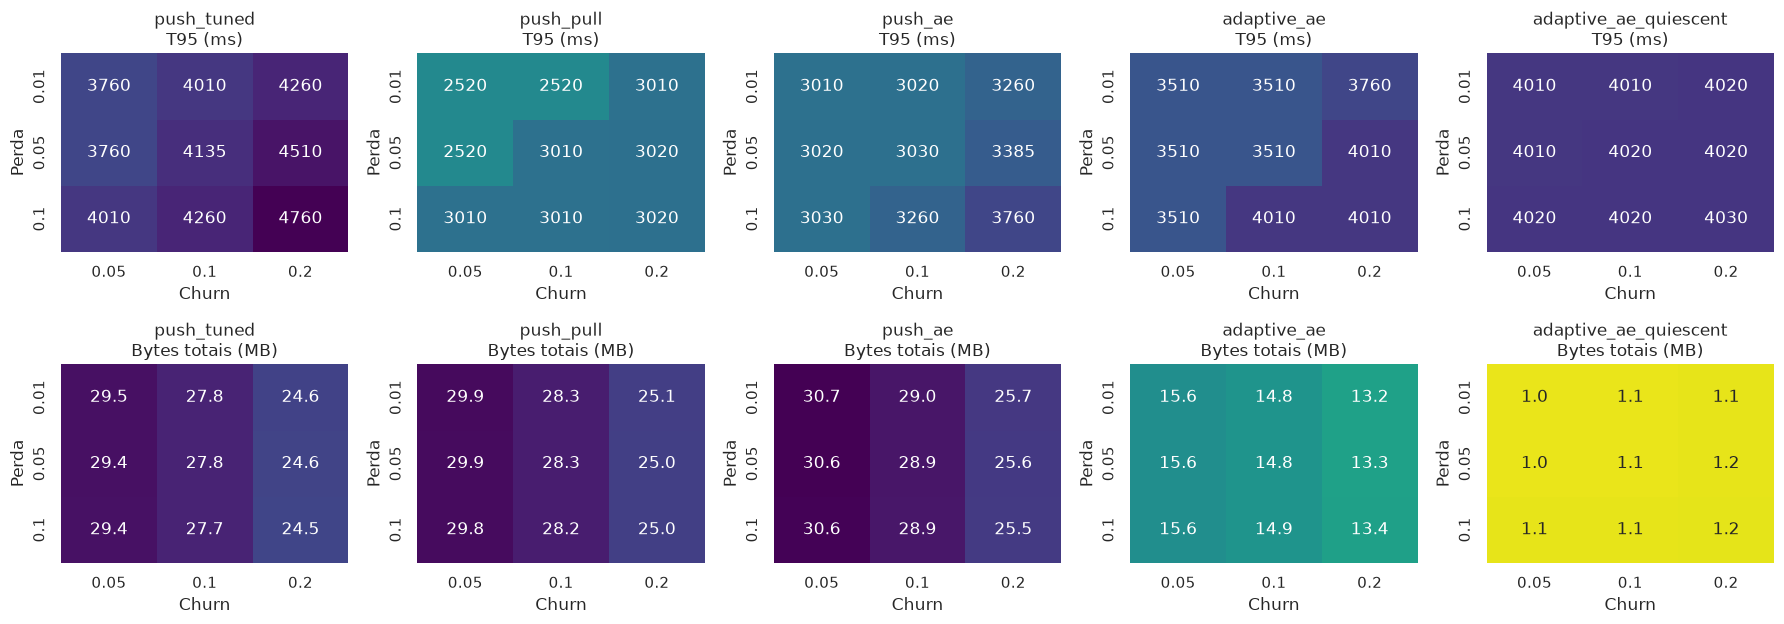

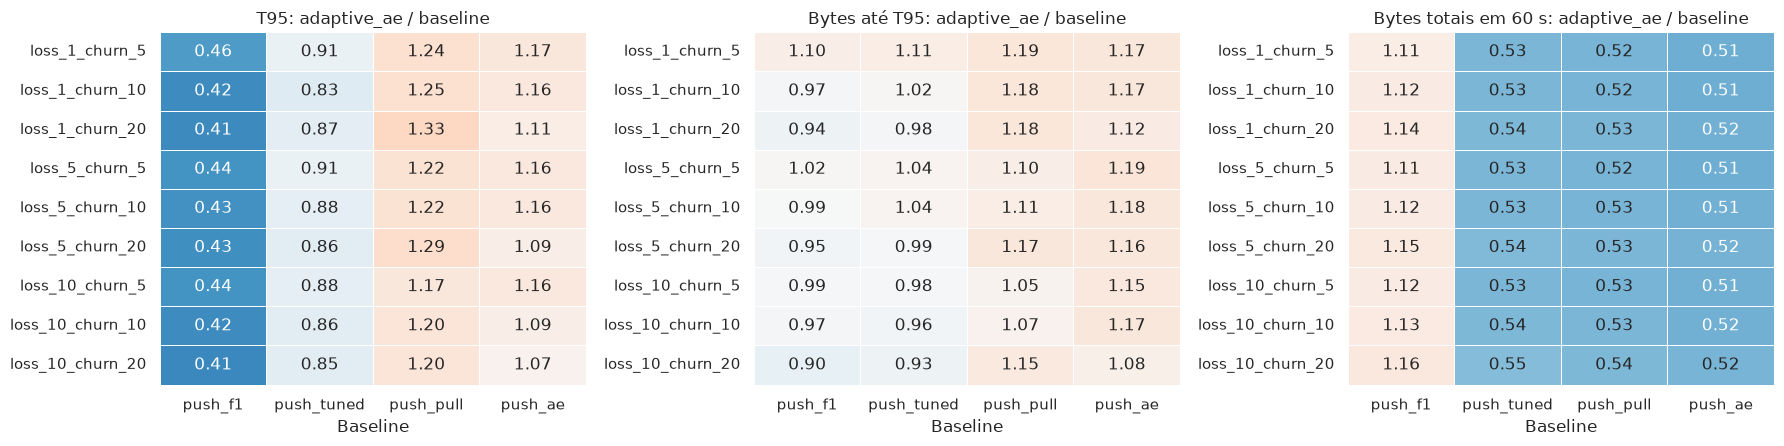

In [16]:
interaction = summary_df[summary_df["phase"] == "interaction"]
assert len(interaction) == 3_240
print(f"Execuções da interação com T95: {interaction['t95_ms'].notna().mean():.3f}")

# mediana de T95 (linha de cima) e de bytes totais (linha de baixo) em N=500, por perda × churn
shown = ["push_tuned", "push_pull", "push_ae", "adaptive_ae", "adaptive_ae_quiescent"]
data = interaction[interaction["n_nodes"] == 500]
fig, axes = plt.subplots(2, len(shown), figsize=(3.6 * len(shown), 6.4))
for row, (metric, label, scale, fmt) in enumerate(
    (("t95_ms", "T95 (ms)", 1, ".0f"), ("bytes_total", "Bytes totais (MB)", 1e-6, ".1f"))
):
    tables = {
        variant: data[data["protocol_variant"] == variant]
        .pivot_table(index="packet_loss", columns="churn_fraction", values=metric, aggfunc="median") * scale
        for variant in shown
    }
    vmax = max(table.to_numpy().max() for table in tables.values())
    for ax, (variant, table) in zip(axes[row], tables.items()):
        sns.heatmap(table, annot=True, fmt=fmt, cmap="viridis_r", vmin=0, vmax=vmax, cbar=False, ax=ax)
        ax.set(title=f"{variant}\n{label}", xlabel="Churn", ylabel="Perda")
plt.tight_layout()
plt.show()

# razão adaptive_ae / baseline nas nove combinações, N=100 e N=500 juntos
ratio_heatmaps(interaction, "adaptive_ae", BASELINES, list(dict.fromkeys(interaction["scenario"])))

### 7.3 Efeito do orçamento de bytes

O orçamento limita os bytes que cada nó envia por janela de 1.000 ms: 2.048 ou 4.096 bytes. Uma `DATA` tem 272 bytes, então os tetos são 7 e 15 `DATA` por janela. A tabela mostra, para cada variante, quantas mensagens o orçamento barrou e a razão pareada entre os dois orçamentos (mesmo cenário, N e seed).

In [17]:
by_budget = main.pivot(
    index=["scenario", "n_nodes", "seed", "protocol_variant"], columns=BUDGET,
    values=["t95_ms", "bytes_total", "budget_drops"],
)
budget_effect = pd.DataFrame(
    {
        "execuções com mensagens barradas, 2.048": (by_budget["budget_drops"][2048] > 0).groupby(level="protocol_variant").mean(),
        "execuções com mensagens barradas, 4.096": (by_budget["budget_drops"][4096] > 0).groupby(level="protocol_variant").mean(),
        "mensagens barradas por nó, mediana, 2.048": (
            by_budget["budget_drops"][2048] / by_budget.index.get_level_values("n_nodes")
        ).groupby(level="protocol_variant").median(),
        "T95: 2.048 / 4.096, mediana dos pares": (by_budget["t95_ms"][2048] / by_budget["t95_ms"][4096]).groupby(level="protocol_variant").median(),
        "bytes totais: 2.048 / 4.096, mediana dos pares": (by_budget["bytes_total"][2048] / by_budget["bytes_total"][4096]).groupby(level="protocol_variant").median(),
    }
).loc[VARIANTS]
display(budget_effect.round(3))

,"execuções com mensagens barradas, 2.048","execuções com mensagens barradas, 4.096","mensagens barradas por nó, mediana, 2.048","T95: 2.048 / 4.096, mediana dos pares","bytes totais: 2.048 / 4.096, mediana dos pares"
protocol_variant,,,,,
push_f1,0.000,0.0,0.000,1.0,1.000
push_tuned,0.000,0.0,0.000,1.0,1.000
push_pull,0.719,0.0,0.010,1.0,1.000
push_ae,0.359,0.0,0.000,1.0,1.000
adaptive_ae,0.909,0.0,0.028,1.0,1.000
adaptive_ae_quiescent,0.878,0.0,0.022,1.0,0.999


### 7.4 Varredura de escala

Os parâmetros foram congelados em N=50. Os gráficos juntam o DOE principal (N=50 a 500) e a varredura (N=1.000 a 100.000) nos três cenários comuns, com orçamento de 4.096 bytes. Em rede completa sem falhas, a teoria do Push prevê cerca de log2(N) + ln(N) rodadas até a cobertura total. Na topologia regular de grau 8, espera-se crescimento também logarítmico, com outra constante: T95 fica próximo de uma reta no eixo N logarítmico.

Fração de execuções da varredura de escala com T95:


protocol_variant     push_f1  push_tuned  push_pull  push_ae  adaptive_ae  adaptive_ae_quiescent
scenario    n_nodes                                                                             
churn_10pct 1000         1.0         1.0        1.0      1.0          1.0                    1.0
            10000        1.0         1.0        1.0      1.0          1.0                    1.0
            100000       1.0         1.0        1.0      1.0          1.0                    1.0
loss_5pct   1000         1.0         1.0        1.0      1.0          1.0                    1.0
            10000        1.0         1.0        1.0      1.0          1.0                    1.0
            100000       1.0         1.0        1.0      1.0          1.0                    1.0
stable      1000         1.0         1.0        1.0      1.0          1.0                    1.0
            10000        1.0         1.0        1.0      1.0          1.0                    1.0
            100000       1.0         1.0        1.0      1.0          1.0                    1.0

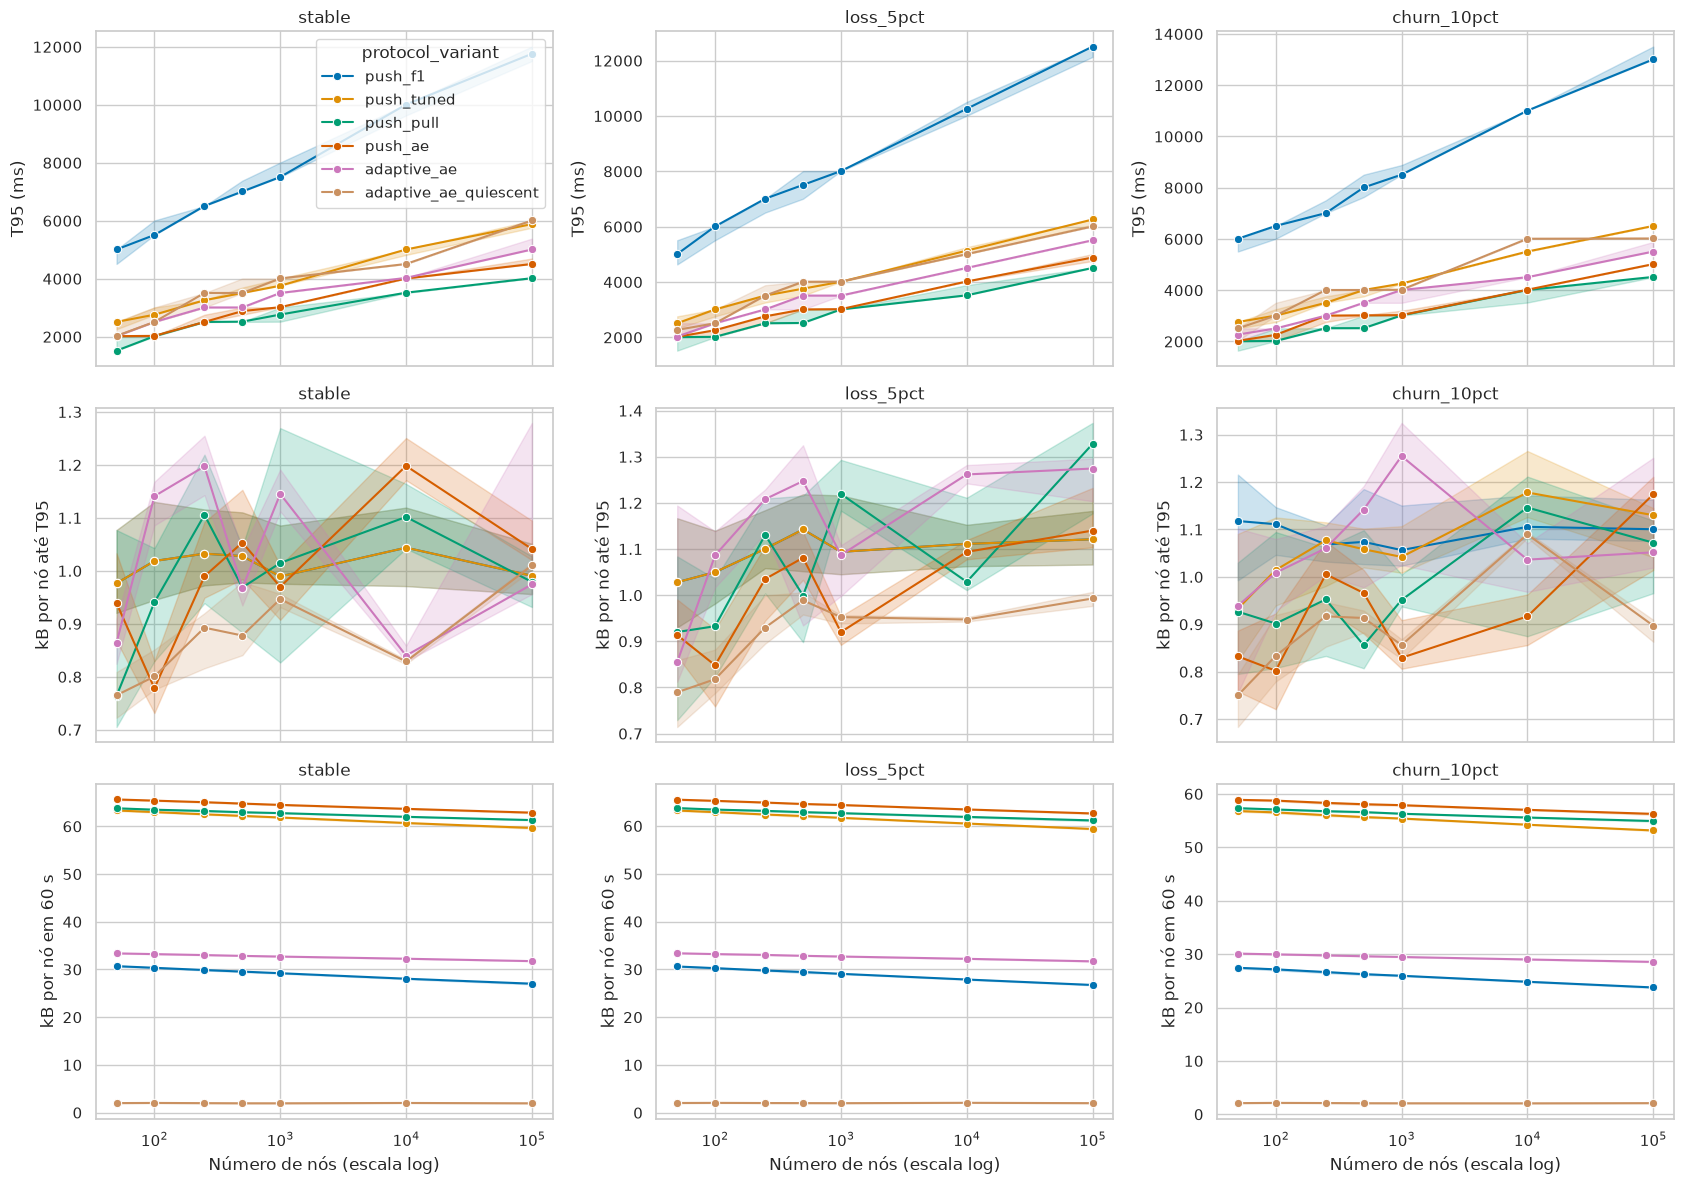

Mediana de T95 (ms), cenário estável, por N:


protocol_variant,push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
n_nodes,,,,,,
50,5010.0,2510.0,1520.0,2020.0,2020.0,2030.0
100,5510.0,2760.0,2020.0,2030.0,2510.0,2510.0
250,6510.0,3260.0,2510.0,2510.0,3010.0,3510.0
500,7010.0,3510.0,2520.0,2885.0,3010.0,3510.0
1000,7510.0,3760.0,2765.0,3020.0,3510.0,4010.0
10000,10010.0,5010.0,3520.0,4010.0,4030.0,4510.0
100000,11760.0,5885.0,4020.0,4510.0,5010.0,6010.0


Mediana de kB por nó até T95, cenário estável, por N:


protocol_variant,push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
n_nodes,,,,,,
50,0.98,0.98,0.76,0.94,0.86,0.77
100,1.02,1.02,0.94,0.78,1.14,0.80
250,1.03,1.03,1.11,0.99,1.20,0.89
500,1.03,1.03,0.97,1.05,0.97,0.88
1000,0.99,0.99,1.01,0.97,1.15,0.95
10000,1.04,1.04,1.10,1.20,0.84,0.83
100000,0.99,0.99,0.98,1.04,0.97,1.01


In [18]:
# varredura de escala, orçamento de 4.096 bytes: N=50 a 500 vem do DOE principal (30 seeds),
# N=1.000 a 100.000 vem de doe_scale.csv (10 seeds). Mediana e quartis; eixo N em escala log
scale_data = pd.concat(
    [main[main[BUDGET] == 4096].drop(columns=["phase", BUDGET, "packet_loss", "churn_fraction"]), scale_summary],
    ignore_index=True,
)
scale_data = scale_data[scale_data["scenario"].isin(set(scale_summary["scenario"]))].assign(
    kb_per_node_until_t95=lambda d: d["bytes_until_t95"] / d["n_nodes"] / 1e3,
    kb_per_node_total=lambda d: d["bytes_total"] / d["n_nodes"] / 1e3,
)
print("Fração de execuções da varredura de escala com T95:")
display(
    scale_summary.assign(reached=scale_summary["t95_ms"].notna())
    .groupby(["scenario", "n_nodes", "protocol_variant"])["reached"].mean().unstack()[VARIANTS]
)

scale_scenarios = ["stable", "loss_5pct", "churn_10pct"]
fig, axes = plt.subplots(3, 3, figsize=(17, 12), sharex=True)
for row, (column, label) in enumerate(
    (("t95_ms", "T95 (ms)"), ("kb_per_node_until_t95", "kB por nó até T95"), ("kb_per_node_total", "kB por nó em 60 s"))
):
    for ax, scenario in zip(axes[row], scale_scenarios):
        sns.lineplot(
            data=scale_data[scale_data["scenario"] == scenario], x="n_nodes", y=column,
            hue="protocol_variant", hue_order=VARIANTS, palette=PALETTE,
            estimator="median", errorbar=("pi", 50), marker="o", ax=ax,
            legend=(row == 0 and scenario == "stable"),
        )
        ax.set(xscale="log", title=scenario, xlabel="Número de nós (escala log)", ylabel=label)
plt.tight_layout()
plt.show()

print("Mediana de T95 (ms), cenário estável, por N:")
display(
    scale_data[scale_data["scenario"] == "stable"]
    .pivot_table(index="n_nodes", columns="protocol_variant", values="t95_ms", aggfunc="median")[VARIANTS]
)
print("Mediana de kB por nó até T95, cenário estável, por N:")
display(
    scale_data[scale_data["scenario"] == "stable"]
    .pivot_table(index="n_nodes", columns="protocol_variant", values="kb_per_node_until_t95", aggfunc="median")[VARIANTS]
    .round(2)
)

### 7.5 Ablação da quiescência e recuperação após a partição

`adaptive_ae_quiescent` difere de `adaptive_ae` só pela quiescência. A comparação mede os bytes que a suspensão do Push remove e o custo em T95, em cobertura e em `recovery_ms` (tempo entre a reconexão em t=20 s e T95).

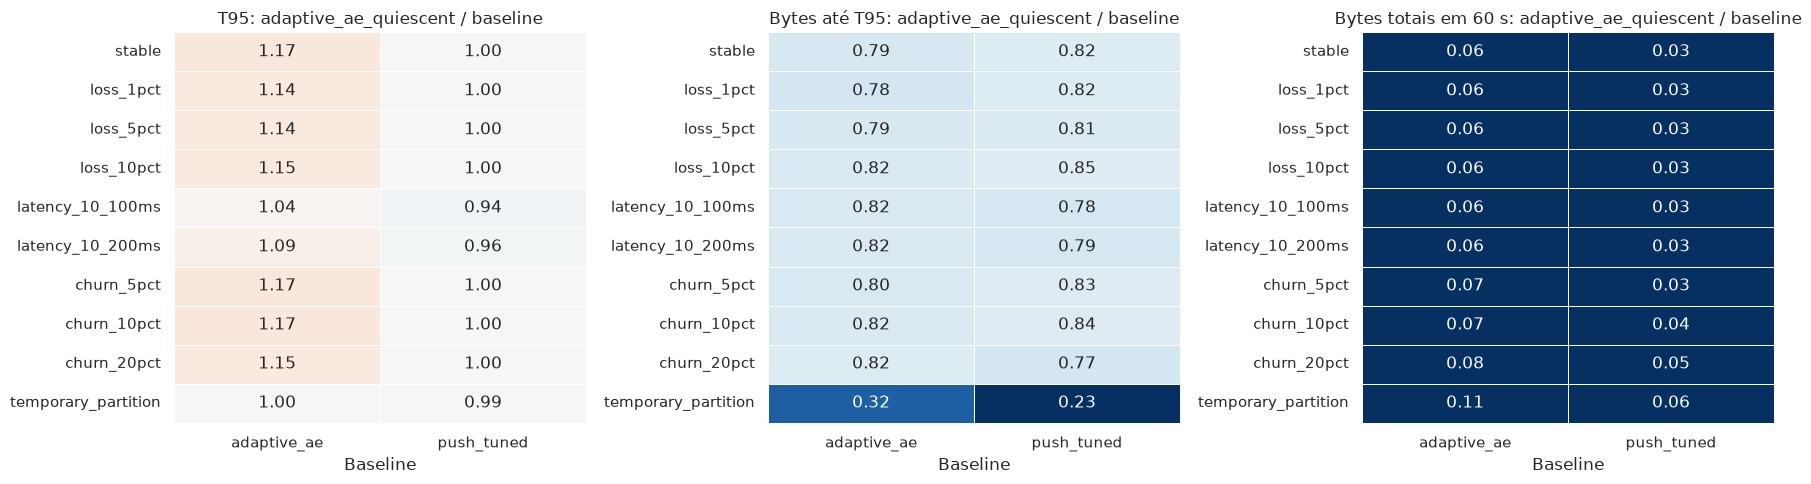

Cobertura final mínima e fração de execuções com T95, por variante:


,coverage_final_min,reached_t95,runs
protocol_variant,,,
adaptive_ae,1.0,1.0,2400
adaptive_ae_quiescent,1.0,1.0,2400


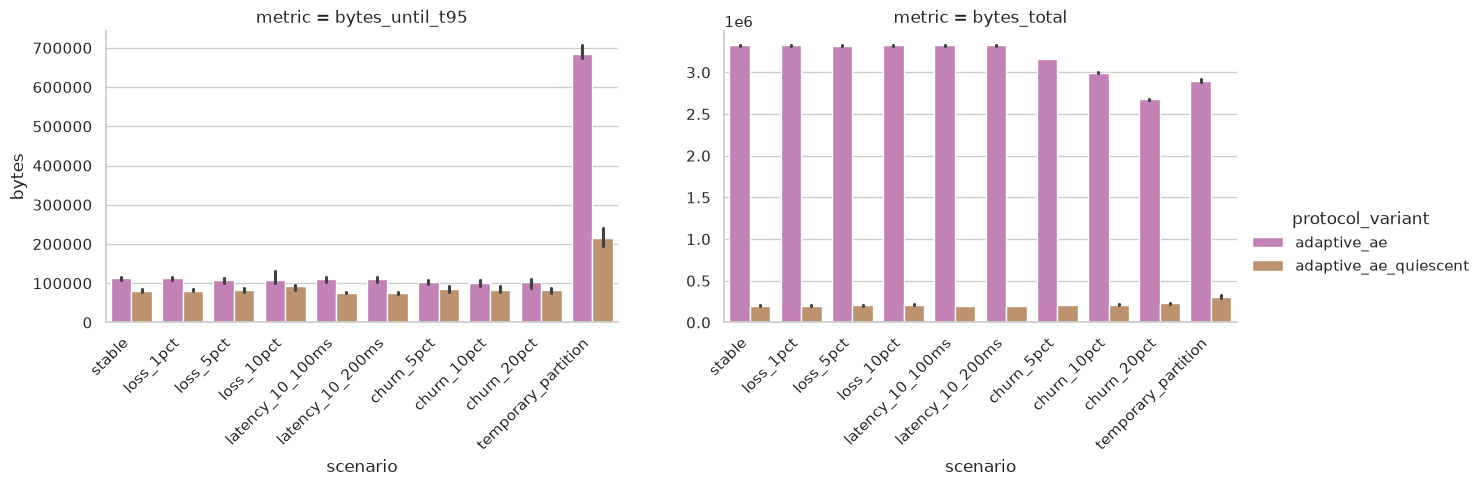

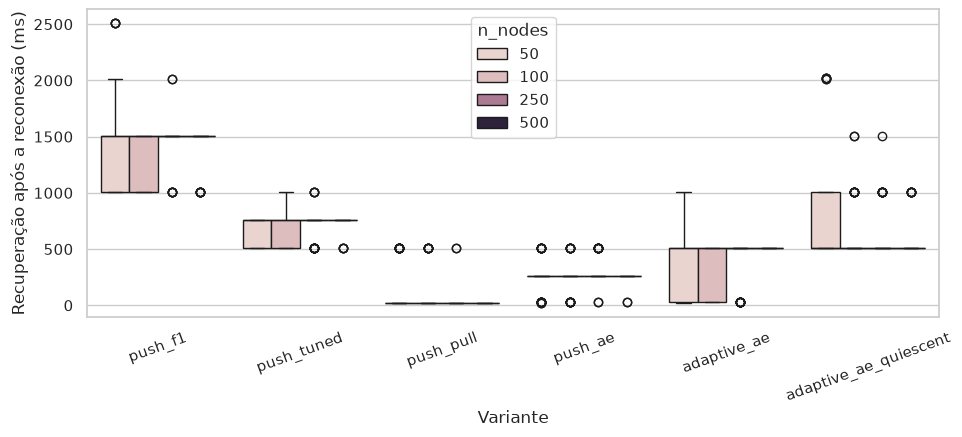

"recovery_ms, mediana",push_f1,push_tuned,push_pull,push_ae,adaptive_ae,adaptive_ae_quiescent
N,,,,,,
50,1510.0,760.0,20.0,260.0,510.0,510.0
100,1510.0,760.0,20.0,260.0,510.0,510.0
250,1510.0,760.0,20.0,260.0,510.0,510.0
500,1510.0,760.0,20.0,260.0,510.0,510.0


In [19]:
# ablação da quiescência: adaptive_ae_quiescent contra adaptive_ae, pareadas por cenário, N, orçamento e seed
ratio_heatmaps(main, "adaptive_ae_quiescent", ["adaptive_ae", "push_tuned"], SCENARIOS)

ablation = main[main["protocol_variant"].isin(["adaptive_ae", "adaptive_ae_quiescent"])]
print("Cobertura final mínima e fração de execuções com T95, por variante:")
display(
    ablation.assign(reached=ablation["t95_ms"].notna())
    .groupby("protocol_variant").agg(coverage_final_min=("coverage_final", "min"), reached_t95=("reached", "mean"), runs=("run_id", "size"))
)

# bytes até T95 e bytes totais por cenário, N=100, orçamento de 4.096 bytes
data = ablation[(ablation["n_nodes"] == 100) & (ablation[BUDGET] == 4096)].melt(
    id_vars=["scenario", "protocol_variant"], value_vars=["bytes_until_t95", "bytes_total"],
    var_name="metric", value_name="bytes",
)
grid = sns.catplot(
    data=data, kind="bar", x="scenario", y="bytes", hue="protocol_variant", palette=PALETTE,
    col="metric", estimator="median", errorbar=("pi", 50), sharey=False, height=4, aspect=1.6,
)
grid.set_xticklabels(rotation=45, ha="right")
plt.show()

# custo da quiescência: recuperação após a partição (reconexão em t=20 s)
partition = main[main["scenario"] == "temporary_partition"]
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=partition, x="protocol_variant", order=VARIANTS, y="recovery_ms", hue="n_nodes", ax=ax)
ax.set(xlabel="Variante", ylabel="Recuperação após a reconexão (ms)")
ax.tick_params(axis="x", rotation=20)
plt.show()
display(
    partition.pivot_table(index="n_nodes", columns="protocol_variant", values="recovery_ms", aggfunc="median")[VARIANTS]
    .rename_axis(index="N", columns="recovery_ms, mediana")
)

## 8. Conclusões

Pergunta do estudo: o fanout adaptativo reduz o tráfego sem piorar T95 ou cobertura? Em quais casos ele perde?

Os números abaixo são medianas. Salvo indicação, valem para N=100 e orçamento de 4.096 bytes, com 30 seeds. As razões são medianas de pares com o mesmo cenário, N, orçamento e seed, nos quatro tamanhos e nos dois orçamentos da fase principal.

**Validação.** Em rede completa, N=100 e 30 seeds, a cobertura média simulada difere do modelo analítico em no máximo 0,007 (fanout 1) e 0,006 (fanout 3) nas 20 rodadas.

**Parâmetros escolhidos em N=50.**

| Variante | Parâmetros |
|---|---|
| `push_tuned` | fanout 1, rodada a cada 250 ms |
| `push_pull` | fanout 2, rodada a cada 500 ms |
| `push_ae` | fanout 1, rodada a cada 250 ms, anti-entropy a cada 1.000 ms |
| `adaptive_ae` | fanout de 1 a 3, `duplicate_threshold` 0,38, `timeout_threshold` 0,68, anti-entropy a cada 2.000 ms |
| `adaptive_ae_quiescent` | os de `adaptive_ae`, com `quiescence_rounds` 1 |

As três famílias de fanout fixo ficaram com a mesma taxa de envio depois da saturação: 4 `DATA` por nó por segundo.

**Cobertura.** As 17.640 execuções do DOE e as 540 da varredura de escala atingiram 95% de cobertura e terminaram com cobertura 1,0. A cobertura não diferencia as variantes.

**T95 e tráfego no cenário estável.**

| Variante | T95 (ms) | Bytes até T95 (kB) | Bytes em 60 s (MB) |
|---|---|---|---|
| `push_f1` | 5.510 | 102 | 3,04 |
| `push_tuned` | 2.760 | 102 | 6,30 |
| `push_pull` | 2.020 | 94 | 6,35 |
| `push_ae` | 2.030 | 78 | 6,54 |
| `adaptive_ae` | 2.510 | 114 | 3,32 |
| `adaptive_ae_quiescent` | 2.510 | 80 | 0,20 |

**Resposta à pergunta.** A hipótese vale em parte. As faixas abaixo cobrem os nove cenários sem partição; na partição, T95 é fixado pela reconexão e as razões de T95 ficam entre 0,99 e 1,02.

- Tráfego total: `adaptive_ae` envia cerca de metade dos bytes das três famílias de fanout fixo ajustadas. A razão pareada fica entre 0,51 e 0,56 em todos os cenários, e o adaptativo envia menos em 100% dos pares.
- T95 contra o Push ajustado: `adaptive_ae` é mais rápido. Razão de 0,86 a 0,89; perde em no máximo 6% dos pares.
- T95 contra Push-Pull e Push + AE: `adaptive_ae` é mais lento. Razão de 1,20 a 1,24 contra `push_pull` (cerca de 500 ms, uma rodada) e de 1,07 a 1,15 contra `push_ae`. Ele perde em 85% a 100% dos pares contra `push_pull` e em 67% a 92% contra `push_ae`. O teste de Wilcoxon dá p < 1e-21 em todos os cenários.
- A economia vem do tráfego depois da saturação. O custo de disseminar é quase o mesmo para todas as variantes: entre 0,75 e 1,3 kB por nó até T95, de N=50 a N=100.000. Até T95, `adaptive_ae` gasta de 1% a 15% mais que `push_pull` e `push_ae`, porque começa com fanout 3.
- Por isso a razão de 0,5 depende de `duration_ms`. T95 ocorre perto de 2,5 s e a execução dura 60 s; com um horizonte menor, a economia seria menor.

**Casos em que o adaptativo perde.**

- T95 contra `push_pull` e `push_ae`, em todos os cenários sem partição.
- Bytes totais contra `push_f1`: 10% a 17% a mais, em 100% dos pares. Em troca, T95 é 55% a 59% menor.
- Bytes até T95 contra `push_pull` e `push_ae`: 1% a 15% a mais.

**Perda e churn juntos (N=500).** Entre a combinação mais leve (perda 1%, churn 5%) e a mais pesada (perda 10%, churn 20%), T95 de `adaptive_ae` sobe de 3.510 para 4.010 ms, o de `push_tuned` de 3.760 para 4.760 ms, o de `push_pull` de 2.520 para 3.020 ms e o de `push_ae` de 3.010 para 3.760 ms. As razões entre variantes são as mesmas da fase principal. Nenhuma combinação deixou execução sem T95.

O limiar `timeout_threshold` de 0,68 exige 4 timeouts em 5 trocas. Com perda de 10% e churn de 20%, uma troca fica sem resposta em cerca de 35% dos casos, então a regra de aumento do fanout dispara pouco. Nos cenários do DOE, o adaptativo age quase só pela regra de redução: começa com fanout 3 e cai para 1. Isso é uma inferência a partir dos parâmetros; o fanout de cada nó ao longo do tempo não foi registrado.

**Orçamento.** Os parâmetros escolhidos usam menos que os dois tetos. Com 4.096 bytes, nenhuma mensagem foi barrada. Com 2.048 bytes, 91% das execuções de `adaptive_ae` e 72% das de `push_pull` tiveram alguma mensagem barrada, mas T95 e bytes não mudaram (razão pareada de 1,00). O fator orçamento não diferenciou as variantes neste DOE.

**Escala.** Os parâmetros ajustados em N=50 continuam funcionando em N=100.000.

- T95 cresce de forma linear com log N. No cenário estável, de N=50 a N=100.000: `push_f1` de 5.010 para 11.760 ms, `push_tuned` de 2.510 para 5.885 ms, `push_pull` de 1.520 para 4.020 ms, `push_ae` de 2.020 para 4.510 ms e `adaptive_ae` de 2.020 para 5.010 ms.
- A cada multiplicação de N por 10, T95 aumenta cerca de 2.050 ms em `push_f1` e 1.020 ms em `push_tuned` (4 rodadas nos dois), 760 ms em `push_pull`, 750 ms em `push_ae` e 910 ms em `adaptive_ae`.
- O custo por nó até T95 fica entre 0,75 e 1,3 kB em todos os tamanhos e cenários.
- A economia do adaptativo se mantém: a razão de bytes totais contra `push_tuned` é 0,53 em N=1.000, 10.000 e 100.000.

**Quiescência (ablação).**

- `adaptive_ae_quiescent` envia de 6% a 8% dos bytes totais de `adaptive_ae` (11% na partição) e de 3% a 6% dos de `push_tuned`. A razão contra `adaptive_ae` é a mesma em N=100.000: 6% a 7%.
- O custo é T95 de 4% a 17% maior que o de `adaptive_ae` no DOE principal. Na varredura de escala, a diferença chega a 33% (churn de 10%, N=10.000). Na partição não há diferença.
- Cobertura final 1,0 nas 2.400 execuções da fase principal, todas com T95. `recovery_ms` é igual ao de `adaptive_ae`: 510 ms.
- O overhead de controle sobe para 22% a 52% dos bytes, porque sobra quase só a anti-entropy.
- `quiescence_rounds` = 1 foi escolhido por desempate. A fronteira de Pareto da grade tem dois pontos (1 e 2), que ficam à mesma distância de (0, 0) depois da normalização; a regra desempata pelo menor tráfego.

**Recuperação após a partição.** `recovery_ms` não depende de N de 50 a 500: `push_pull` 20 ms, `push_ae` 260 ms, `adaptive_ae` e `adaptive_ae_quiescent` 510 ms, `push_tuned` 760 ms, `push_f1` 1.510 ms. O valor de `push_pull` vem do alinhamento do modelo: a reconexão em t=20 s coincide com uma rodada, e os nós sem a atualização pedem a dois peers nessa rodada.

**Limitações.**

- Uma única atualização por execução. Não há atualizações concorrentes nem versões sucessivas.
- Perdas independentes por mensagem, topologia regular estática de grau 8 e visão de peers estática.
- O churn troca o conjunto offline de uma vez a cada 5 s, e a partição começa e termina em múltiplos do intervalo de gossip.
- `bytes_total` depende do horizonte de 60 s. As razões de tráfego total entre variantes mudam com `duration_ms`.
- Um estudo de 30 trials por família. O espaço de busca das famílias de fanout fixo tem 15 ou 45 combinações, e o TPE repetiu configurações.
- A escolha na fronteira de Pareto usa uma regra fixa. Outra regra daria outro ponto de operação; as famílias de fanout fixo têm pontos na fronteira com metade do tráfego e T95 maior.
- `wall_time_s` foi medido com 14 a 32 processos em paralelo em um notebook, e inclui a disputa por CPU.
- A simulação de eventos discretos mede o comportamento dos algoritmos. Ela não mede custos de rede real, sockets ou containers.